# Predicting Diabetes Risk from Health Survey Data
## Capstone 20.1: Initial Report and Exploratory Data Analysis

**Author:** Santosh Kumar

### Contents
1. Problem statement
2. Setup and data loading
3. Data cleaning (missing values, duplicates, outliers)
4. Feature engineering
5. Exploratory data analysis
6. Baseline model and evaluation
7. Conclusions and next steps

## 1. Problem statement

**Research question:** Can lifestyle and health indicators from a national health survey predict whether a person has diabetes, and which factors matter most?

**Why it matters:** Diabetes often goes undetected for years, and complications such as heart disease, kidney damage and vision loss may start before it is found. A simple model built on easy survey questions could help clinics and public health teams decide who to screen first.

**Data:** CDC Behavioral Risk Factor Surveillance System (BRFSS) 2015, in the cleaned Kaggle version *Diabetes Health Indicators Dataset* (253,680 responses, 21 features). The target `Diabetes_binary` is 0 (no diabetes or only during pregnancy) or 1 (prediabetes or diabetes).

**Approach for this report:** clean the data, explore it visually, then fit a baseline classification model. Because far fewer people have diabetes than not, the model is judged mainly on **recall** (how many people with diabetes it finds) and **ROC-AUC**, not on accuracy.

## 2. Setup and data loading

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

In [2]:
raw = pd.read_csv("../data/diabetes_binary_health_indicators_BRFSS2015.csv")
print("Shape:", raw.shape)
raw.head()

Shape: (253680, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  MentHlth   

All 22 columns are numeric. Most are 0/1 flags (for example `HighBP`, `Smoker`), plus a few ordinal scales:
`GenHlth` (1 = excellent to 5 = poor), `Age` (13 age bands), `Education` (1 to 6) and `Income` (1 to 8), and three numeric columns: `BMI`, `MentHlth` and `PhysHlth` (days of poor health in the last 30 days).

## 3. Data cleaning

### 3.1 Missing values

In [4]:
missing = raw.isna().sum()
print("Total missing values:", int(missing.sum()))
print("Columns with missing values:", list(missing[missing > 0].index))

Total missing values: 0
Columns with missing values: []


The dataset has **no missing values**, so no imputation is needed. (Real BRFSS data has "refused" and "don't know" answers; the Kaggle version already removed them.)

### 3.2 Duplicate rows

In [5]:
n_dups = raw.duplicated().sum()
print(f"Duplicate rows: {n_dups:,} ({n_dups / len(raw):.1%})")

df = raw.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 24,206 (9.5%)
Shape after removing duplicates: (229474, 22)


About **9.5%** of the rows are exact duplicates. Most columns are 0/1 flags, so two different people can legitimately give identical answers. We still remove them for two reasons: it stops the same row from landing in both the training and test sets (which would inflate scores), and it is the standard cleaning step. This is noted as a limitation in the conclusions.

### 3.3 Data types and value ranges

In [6]:
# Binary and ordinal columns are stored as floats; convert to integers.
df = df.astype(int)

ranges = df.agg(["min", "max"]).T
ranges["unique_values"] = df.nunique()
ranges

,min,max,unique_values
Diabetes_binary,0,1,2
HighBP,0,1,2
HighChol,0,1,2
CholCheck,0,1,2
BMI,12,98,84
Smoker,0,1,2
Stroke,0,1,2
HeartDiseaseorAttack,0,1,2
PhysActivity,0,1,2
Fruits,0,1,2


All ranges match the data dictionary (flags 0/1, `GenHlth` 1 to 5, `Age` 1 to 13, `MentHlth` and `PhysHlth` 0 to 30). No impossible values were found.

### 3.4 Outlier analysis

In [7]:
numeric_cols = ["BMI", "MentHlth", "PhysHlth"]

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return low, high, ((s < low) | (s > high)).sum()

rows = []
for col in numeric_cols:
    low, high, n = iqr_outliers(df[col])
    rows.append({"feature": col, "lower_fence": low, "upper_fence": high,
                 "n_outliers": n, "pct_outliers": round(100 * n / len(df), 1),
                 "max": df[col].max()})
pd.DataFrame(rows)

,feature,lower_fence,upper_fence,n_outliers,pct_outliers,max
0,BMI,12.0,44.0,5638,2.5,98
1,MentHlth,-3.0,5.0,36162,15.8,30
2,PhysHlth,-6.0,10.0,34346,15.0,30


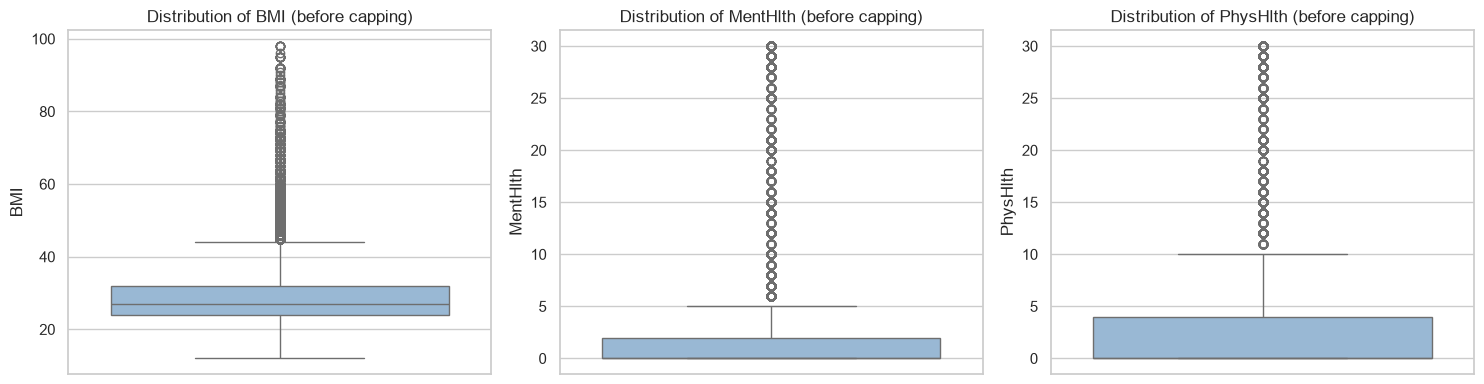

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=df[col], ax=ax, color="#8fb8de")
    ax.set_title(f"Distribution of {col} (before capping)")
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

**Findings:**
- `BMI` has about 5,600 IQR outliers, with values up to 98. Very high BMI values are medically possible, so they are not errors, but the extreme tail can distort a linear model. We **cap** BMI at the 99th percentile instead of deleting rows (see feature engineering).
- `MentHlth` and `PhysHlth` are heavily skewed: most people report 0 bad days, and a group reports all 30. That pattern is real (chronic illness), not an error, so these values are **kept**.

## 4. Feature engineering

In [9]:
# 1) Cap extreme BMI values at the 99th percentile
bmi_cap = df["BMI"].quantile(0.99)
df["BMI_capped"] = df["BMI"].clip(upper=bmi_cap)

# 2) BMI category (WHO bands)
df["BMI_category"] = pd.cut(df["BMI"], bins=[0, 18.5, 25, 30, 200],
                            labels=["Underweight", "Normal", "Overweight", "Obese"], right=False)

# 3) Readable age groups from the 13 BRFSS age bands
age_labels = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
              "55-59", "60-64", "65-69", "70-74", "75-79", "80+"]
df["Age_group"] = pd.Categorical.from_codes(df["Age"] - 1, categories=age_labels)

# 4) Count of health risk flags (higher = more risk factors)
risk_flags = ["HighBP", "HighChol", "Smoker", "Stroke", "HeartDiseaseorAttack", "DiffWalk"]
df["RiskFactorCount"] = df[risk_flags].sum(axis=1)

print(f"BMI cap (99th percentile): {bmi_cap:.0f}")
df[["BMI", "BMI_capped", "BMI_category", "Age", "Age_group", "RiskFactorCount"]].head()

BMI cap (99th percentile): 50


,BMI,BMI_capped,BMI_category,Age,Age_group,RiskFactorCount
0,40,40,Obese,9,60-64,4
1,25,25,Overweight,7,50-54,1
2,28,28,Overweight,9,60-64,3
3,27,27,Overweight,11,70-74,1
4,24,24,Normal,11,70-74,2


Four engineered features were added:
- `BMI_capped`: BMI limited to the 99th percentile, for the model.
- `BMI_category`: standard WHO weight bands, for plots and interpretation.
- `Age_group`: readable labels for the 13 age bands.
- `RiskFactorCount`: how many of six risk flags (high blood pressure, high cholesterol, smoking, stroke, heart disease, difficulty walking) a person has.

## 5. Exploratory data analysis

### 5.1 The target is imbalanced

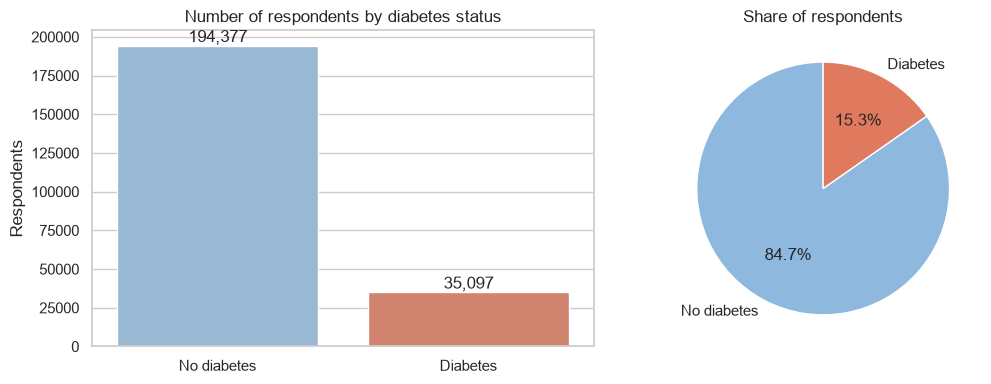

A model that always predicts 'no diabetes' would be 84.7% accurate.


In [10]:
counts = df["Diabetes_binary"].value_counts().sort_index()
labels = ["No diabetes", "Diabetes"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=labels, y=counts.values, ax=axes[0], palette=["#8fb8de", "#e07a5f"])
axes[0].set_title("Number of respondents by diabetes status")
axes[0].set_ylabel("Respondents")
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")

axes[1].pie(counts.values, labels=labels, autopct="%1.1f%%", colors=["#8fb8de", "#e07a5f"], startangle=90)
axes[1].set_title("Share of respondents")
plt.tight_layout()
plt.show()

majority_share = counts.max() / counts.sum()
print(f"A model that always predicts 'no diabetes' would be {majority_share:.1%} accurate.")

Only about 15% of respondents have diabetes. This is why accuracy alone is misleading, and why recall is used as the main metric.

### 5.2 Continuous variables: BMI and unhealthy days

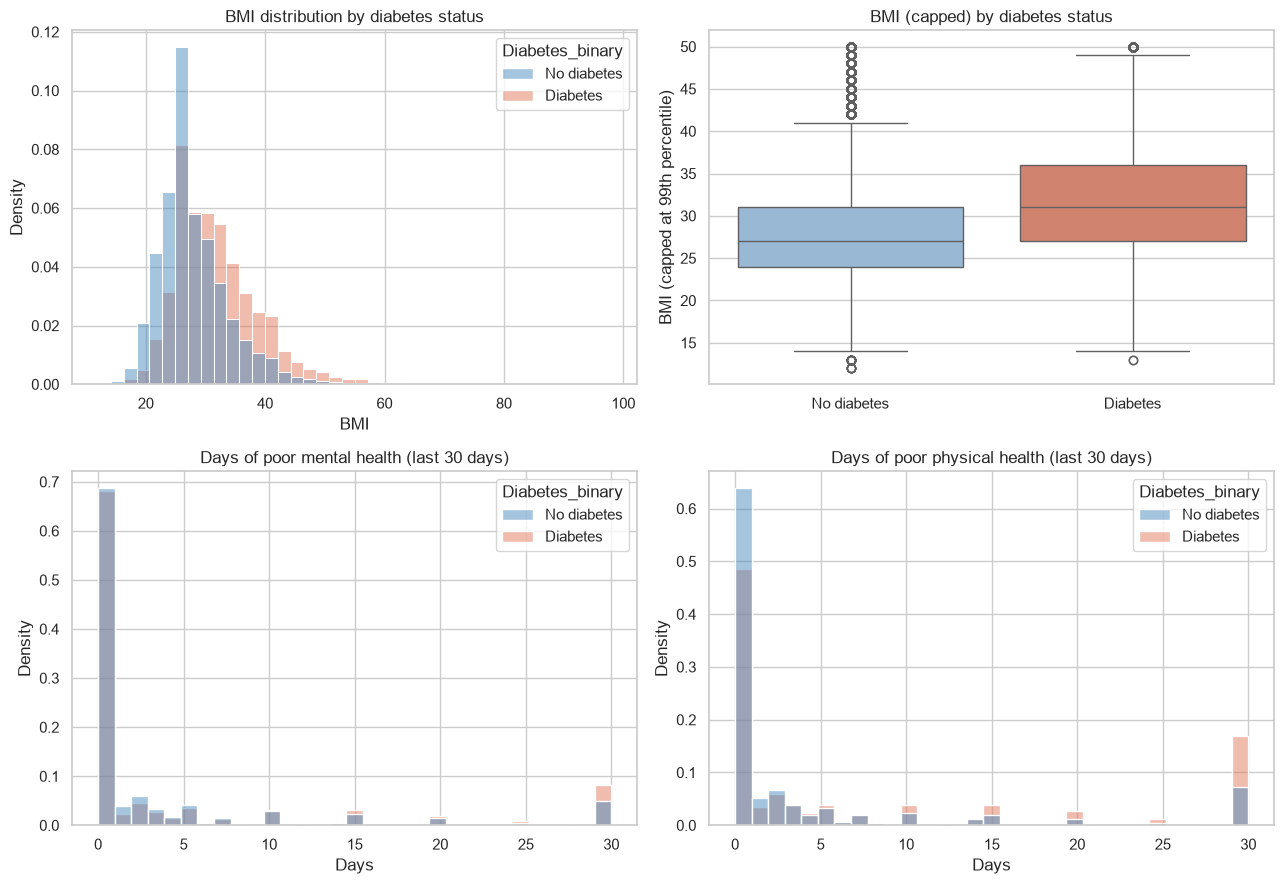

,BMI,MentHlth,PhysHlth
Diabetes_binary,,,
Diabetes,32.0,4.5,8.0
No diabetes,28.1,3.3,4.1


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
status = df["Diabetes_binary"].map({0: "No diabetes", 1: "Diabetes"})

sns.histplot(data=df, x="BMI", hue=status, stat="density", common_norm=False,
             bins=40, ax=axes[0, 0], palette=["#4c8cbf", "#e07a5f"])
axes[0, 0].set_title("BMI distribution by diabetes status")
axes[0, 0].set_xlabel("BMI")

sns.boxplot(x=status, y=df["BMI_capped"], ax=axes[0, 1], palette=["#8fb8de", "#e07a5f"])
axes[0, 1].set_title("BMI (capped) by diabetes status")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("BMI (capped at 99th percentile)")

sns.histplot(data=df, x="MentHlth", hue=status, stat="density", common_norm=False,
             bins=31, ax=axes[1, 0], palette=["#4c8cbf", "#e07a5f"])
axes[1, 0].set_title("Days of poor mental health (last 30 days)")
axes[1, 0].set_xlabel("Days")

sns.histplot(data=df, x="PhysHlth", hue=status, stat="density", common_norm=False,
             bins=31, ax=axes[1, 1], palette=["#4c8cbf", "#e07a5f"])
axes[1, 1].set_title("Days of poor physical health (last 30 days)")
axes[1, 1].set_xlabel("Days")

plt.tight_layout()
plt.show()

means = df.groupby(status)[["BMI", "MentHlth", "PhysHlth"]].mean().round(1)
means

People with diabetes have a higher BMI on average, and their BMI distribution is shifted to the right. They also report more days of poor physical health, with a large group at the maximum of 30 days. Mental health days differ much less.

### 5.3 Binary health and lifestyle factors

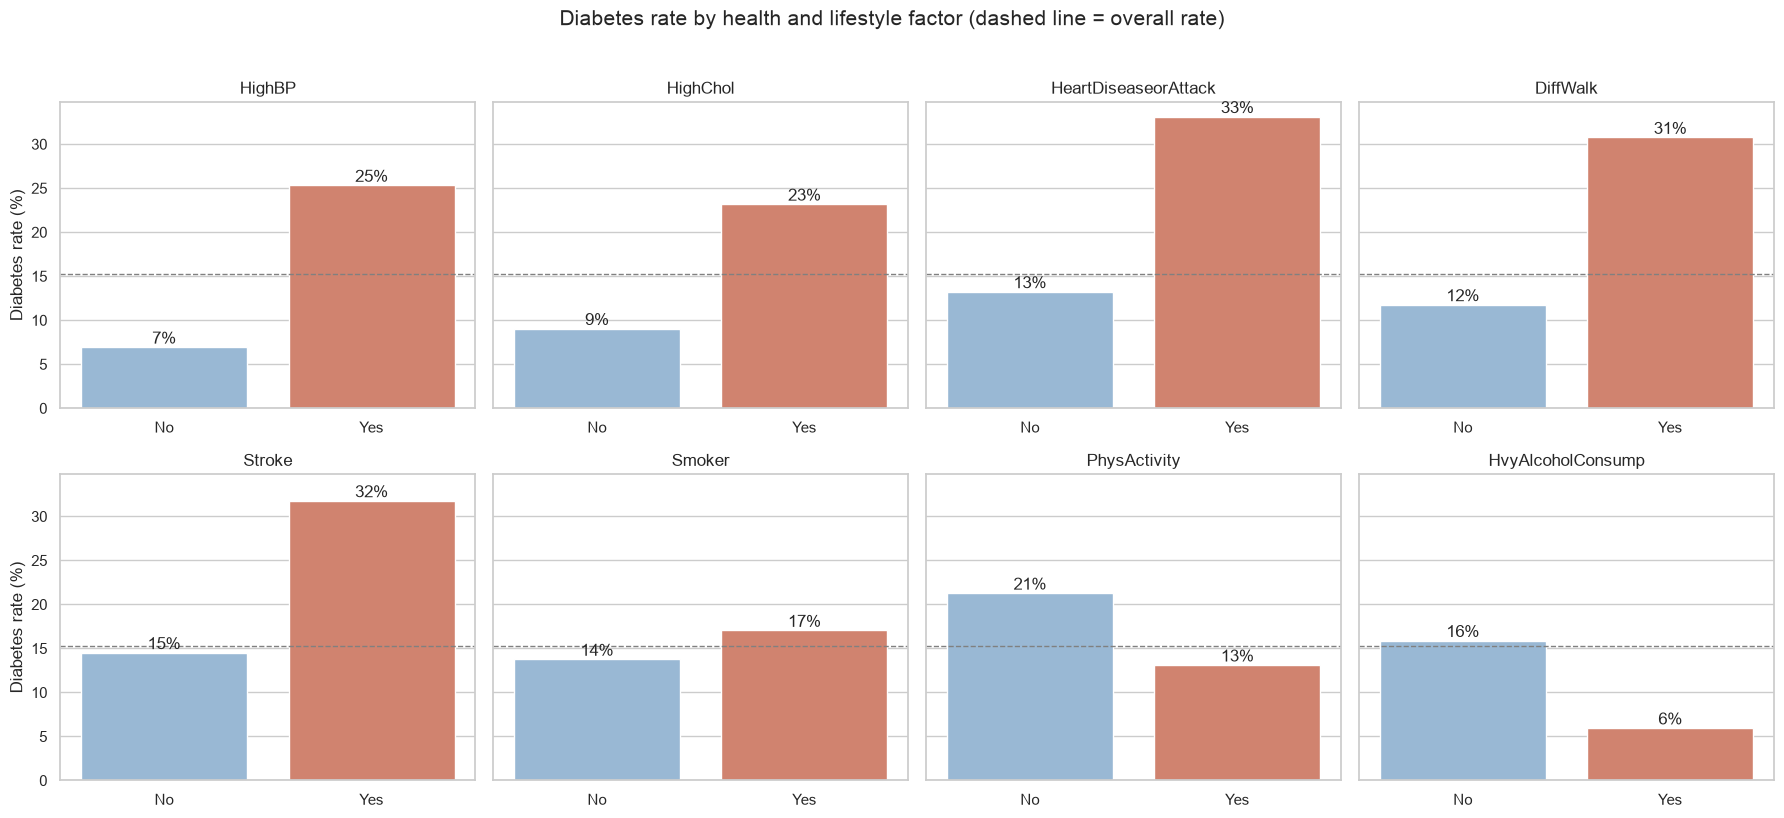

In [12]:
binary_features = ["HighBP", "HighChol", "HeartDiseaseorAttack", "DiffWalk",
                   "Stroke", "Smoker", "PhysActivity", "HvyAlcoholConsump"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
overall = df["Diabetes_binary"].mean() * 100

for ax, col in zip(axes.ravel(), binary_features):
    rate = df.groupby(col)["Diabetes_binary"].mean() * 100
    sns.barplot(x=["No", "Yes"], y=rate.values, ax=ax, palette=["#8fb8de", "#e07a5f"])
    ax.axhline(overall, color="grey", linestyle="--", linewidth=1)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Diabetes rate (%)")
    for i, v in enumerate(rate.values):
        ax.text(i, v, f"{v:.0f}%", ha="center", va="bottom")

fig.suptitle("Diabetes rate by health and lifestyle factor (dashed line = overall rate)", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

High blood pressure, high cholesterol, heart disease, difficulty walking and stroke each go together with a much higher diabetes rate: about two to four times higher than for people without that condition (for example, 25% with high blood pressure versus 7% without). Being physically active goes with a lower rate (13% versus 21%). Smoking has a smaller effect (17% versus 14%), and heavy alcohol use is linked with a *lower* rate (6% versus 16%), which is probably a sign of confounding (for example, people with a diagnosis may drink less), not a protective effect.

### 5.4 Age, general health, income and BMI category

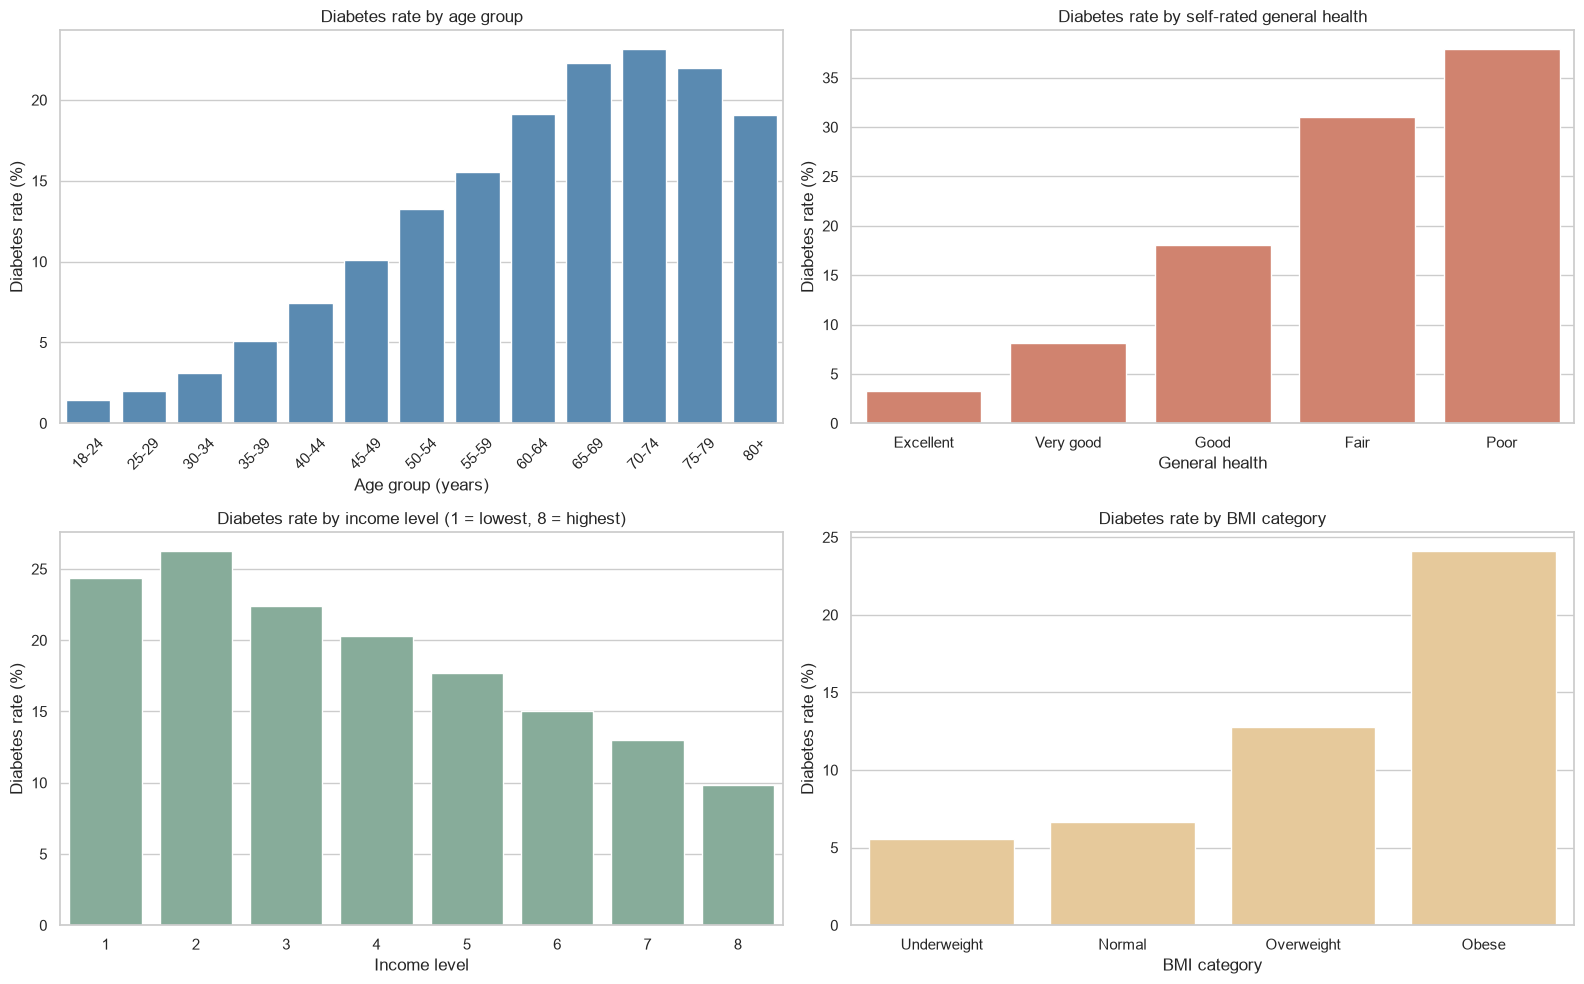

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

age_rate = df.groupby("Age_group", observed=True)["Diabetes_binary"].mean() * 100
sns.barplot(x=age_rate.index, y=age_rate.values, ax=axes[0, 0], color="#4c8cbf")
axes[0, 0].set_title("Diabetes rate by age group")
axes[0, 0].set_xlabel("Age group (years)")
axes[0, 0].set_ylabel("Diabetes rate (%)")
axes[0, 0].tick_params(axis="x", rotation=45)

gh_rate = df.groupby("GenHlth")["Diabetes_binary"].mean() * 100
sns.barplot(x=["Excellent", "Very good", "Good", "Fair", "Poor"], y=gh_rate.values,
            ax=axes[0, 1], color="#e07a5f")
axes[0, 1].set_title("Diabetes rate by self-rated general health")
axes[0, 1].set_xlabel("General health")
axes[0, 1].set_ylabel("Diabetes rate (%)")

inc_rate = df.groupby("Income")["Diabetes_binary"].mean() * 100
sns.barplot(x=inc_rate.index, y=inc_rate.values, ax=axes[1, 0], color="#81b29a")
axes[1, 0].set_title("Diabetes rate by income level (1 = lowest, 8 = highest)")
axes[1, 0].set_xlabel("Income level")
axes[1, 0].set_ylabel("Diabetes rate (%)")

bmi_rate = df.groupby("BMI_category", observed=True)["Diabetes_binary"].mean() * 100
sns.barplot(x=bmi_rate.index.astype(str), y=bmi_rate.values, ax=axes[1, 1], color="#f2cc8f")
axes[1, 1].set_title("Diabetes rate by BMI category")
axes[1, 1].set_xlabel("BMI category")
axes[1, 1].set_ylabel("Diabetes rate (%)")

plt.tight_layout()
plt.show()

- **Age:** the diabetes rate rises steadily with age, from about 1% in the youngest group to a peak of about 23% at ages 70 to 74, then levels off or dips slightly after 75.
- **General health:** the rate climbs sharply as self-rated health gets worse, from about 3% (excellent) to about 38% (poor). This is likely to be one of the strongest predictors.
- **Income:** higher income goes with a lower rate (about 24% at the lowest levels versus 10% at the highest), a sign that social and economic factors matter.
- **BMI category:** the rate is lowest for underweight and normal weight (about 6% to 7%) and highest for the obese group (about 24%).

### 5.5 Risk factor count and correlations

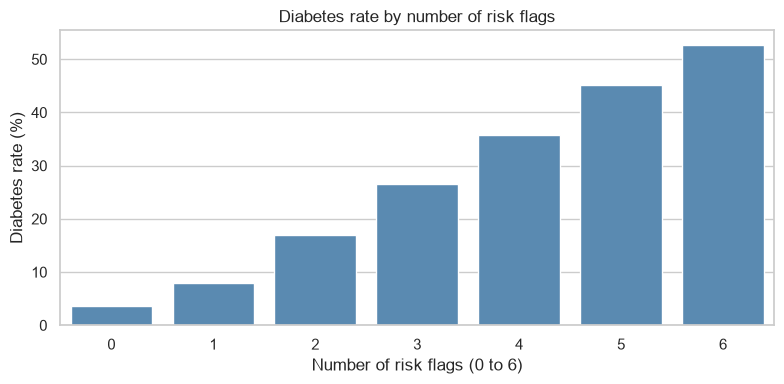

In [14]:
rf_rate = df.groupby("RiskFactorCount")["Diabetes_binary"].agg(["mean", "size"])
rf_rate["mean"] *= 100

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=rf_rate.index, y=rf_rate["mean"].values, ax=ax, color="#4c8cbf")
ax.set_title("Diabetes rate by number of risk flags")
ax.set_xlabel("Number of risk flags (0 to 6)")
ax.set_ylabel("Diabetes rate (%)")
plt.tight_layout()
plt.show()

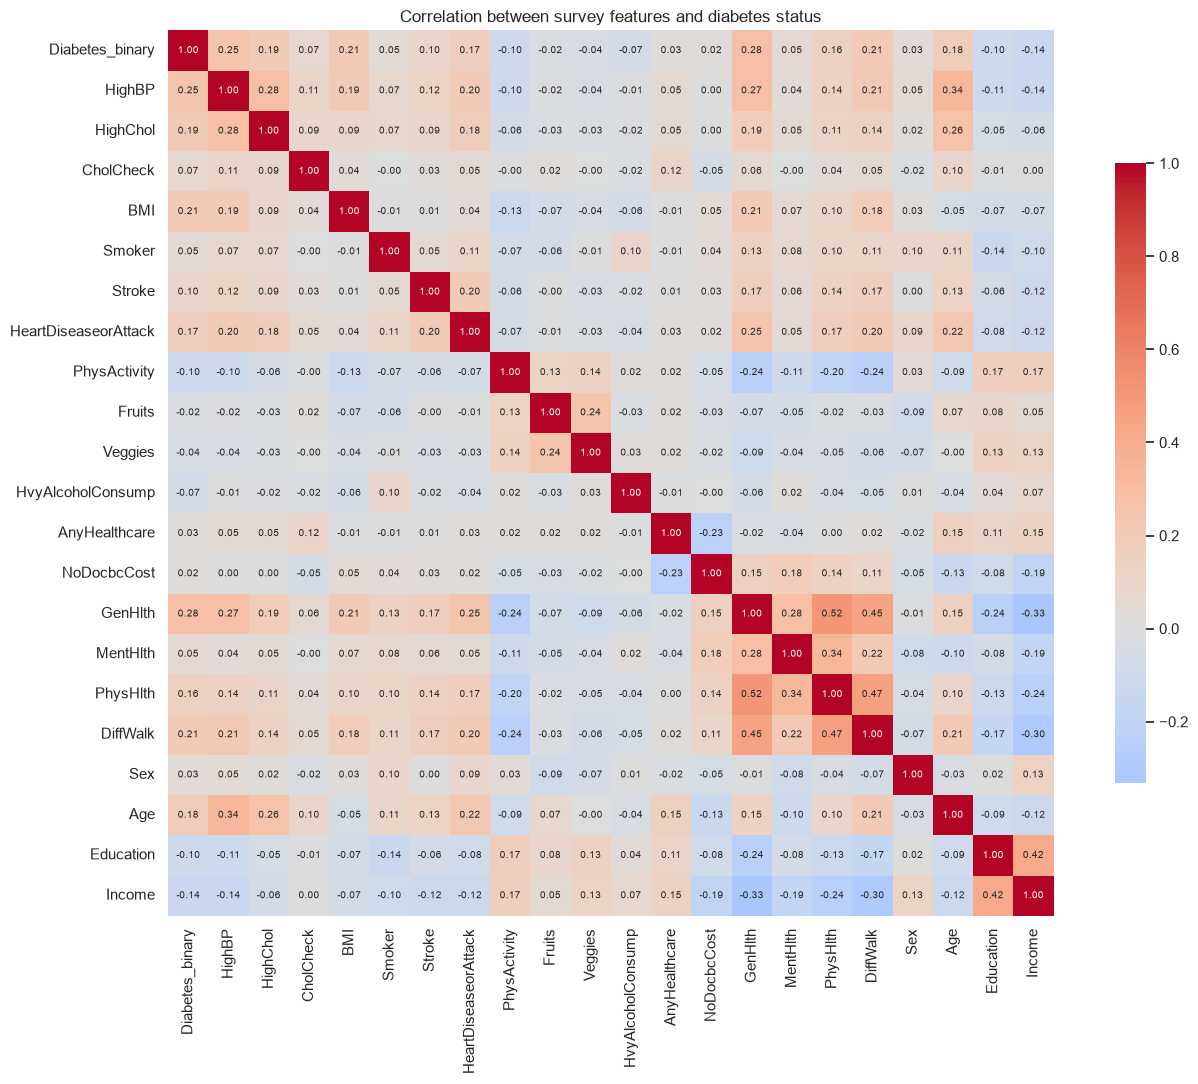

GenHlth                 0.277
HighBP                  0.254
DiffWalk                0.205
BMI                     0.205
HighChol                0.195
Age                     0.177
HeartDiseaseorAttack    0.168
PhysHlth                0.156
Name: Diabetes_binary, dtype: float64

In [15]:
corr_cols = [c for c in raw.columns]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt=".2f", annot_kws={"size": 7}, cmap="coolwarm",
            center=0, square=True, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlation between survey features and diabetes status")
plt.tight_layout()
plt.show()

target_corr = corr["Diabetes_binary"].drop("Diabetes_binary").sort_values(key=abs, ascending=False)
target_corr.head(8).round(3)

The diabetes rate grows steadily with the number of risk flags. In the correlation matrix, the features most related to diabetes are `GenHlth`, `HighBP`, `DiffWalk`, `BMI`, `HighChol`, `Age` and `HeartDiseaseorAttack`. No single feature has a strong correlation (all are below about 0.3), so the model will need to combine many of them. Several features are related to each other (for example `PhysHlth`, `GenHlth` and `DiffWalk`), which is worth remembering when we read model coefficients.

## 6. Baseline model

### 6.1 Model choice and evaluation metric

**Model:** Logistic Regression. It is a simple, fast, well-understood classifier, and its coefficients are easy to explain to non-technical readers. A good baseline should be simple, so later models (tree-based models, tuned models) in Module 24 have something to beat.

**Metric:** the main metric is **recall** for the diabetes class, which is the share of people with diabetes the model finds. In a screening setting, missing a person who has diabetes is worse than a false alarm that leads to an extra test. We also report **ROC-AUC** (how well the model ranks high-risk people above low-risk people, independent of the threshold), plus precision and F1 so the cost of false alarms stays visible. **Accuracy is reported but not used to choose a model**, because 85% of people do not have diabetes.

In [16]:
features = [c for c in raw.columns if c not in ("Diabetes_binary", "BMI")] + ["BMI_capped", "RiskFactorCount"]
X = df[features]
y = df["Diabetes_binary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Diabetes share (train / test):", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

Train: (183579, 22) | Test: (45895, 22)
Diabetes share (train / test): 0.153 / 0.153


In [17]:
models = {
    "Majority-class (always 'no diabetes')": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression (default)": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "Logistic Regression (balanced)": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
}

results = []
fitted = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
    })

results_df = pd.DataFrame(results).set_index("model").round(3)
results_df

,accuracy,recall,precision,f1,roc_auc
model,,,,,
Majority-class (always 'no diabetes'),0.847,0.000,0.000,0.000,0.500
Logistic Regression (default),0.853,0.168,0.562,0.259,0.812
Logistic Regression (balanced),0.715,0.762,0.319,0.450,0.812


In [18]:
base = results_df.loc["Majority-class (always 'no diabetes')"]
default = results_df.loc["Logistic Regression (default)"]
bal = results_df.loc["Logistic Regression (balanced)"]

display(Markdown(f'''
**What the numbers say**

- **Accuracy is misleading.** Always predicting "no diabetes" is {base["accuracy"]:.1%} accurate but finds {base["recall"]:.0%} of people with diabetes.
- **Default Logistic Regression** is {default["accuracy"]:.1%} accurate, but its recall is only {default["recall"]:.1%}: it misses most people with diabetes, because it learns to favour the majority class.
- **Balanced Logistic Regression** (the chosen baseline) gives up some accuracy ({bal["accuracy"]:.1%}) and finds **{bal["recall"]:.1%}** of people with diabetes, with a ROC-AUC of **{bal["roc_auc"]:.3f}**. Its precision is {bal["precision"]:.1%}, so about {1 - bal["precision"]:.0%} of the people it flags do not have diabetes.
- ROC-AUC is almost the same for both logistic models ({default["roc_auc"]:.3f} vs {bal["roc_auc"]:.3f}). The model *ranks* people equally well; balancing only moves the decision threshold so that more at-risk people are flagged.
'''))


**What the numbers say**

- **Accuracy is misleading.** Always predicting "no diabetes" is 84.7% accurate but finds 0% of people with diabetes.
- **Default Logistic Regression** is 85.3% accurate, but its recall is only 16.8%: it misses most people with diabetes, because it learns to favour the majority class.
- **Balanced Logistic Regression** (the chosen baseline) gives up some accuracy (71.5%) and finds **76.2%** of people with diabetes, with a ROC-AUC of **0.812**. Its precision is 31.9%, so about 68% of the people it flags do not have diabetes.
- ROC-AUC is almost the same for both logistic models (0.812 vs 0.812). The model *ranks* people equally well; balancing only moves the decision threshold so that more at-risk people are flagged.


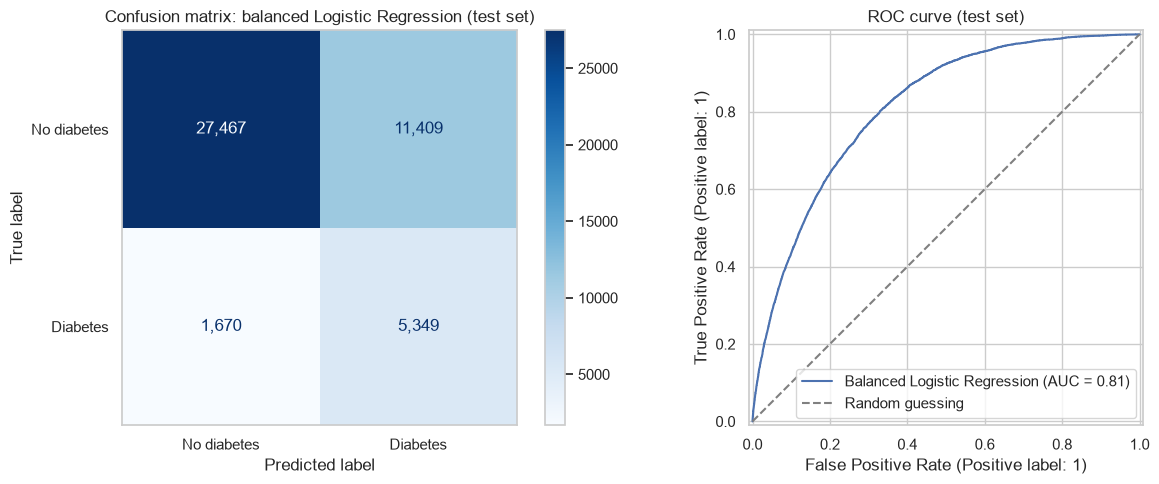

In [19]:
baseline = fitted["Logistic Regression (balanced)"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_estimator(
    baseline, X_test, y_test, display_labels=["No diabetes", "Diabetes"],
    cmap="Blues", values_format=",", ax=axes[0])
axes[0].set_title("Confusion matrix: balanced Logistic Regression (test set)")
axes[0].grid(False)

RocCurveDisplay.from_estimator(baseline, X_test, y_test, ax=axes[1],
                               name="Balanced Logistic Regression")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guessing")
axes[1].set_title("ROC curve (test set)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

### 6.2 Is the result stable? (5-fold cross-validation)

In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_validate(baseline, X, y, cv=cv, scoring=["recall", "roc_auc"], n_jobs=-1)

cv_summary = pd.DataFrame({
    "mean": [cv_scores["test_recall"].mean(), cv_scores["test_roc_auc"].mean()],
    "std": [cv_scores["test_recall"].std(), cv_scores["test_roc_auc"].std()],
}, index=["recall", "roc_auc"]).round(3)
cv_summary

,mean,std
recall,0.755,0.005
roc_auc,0.809,0.003


The cross-validated recall and ROC-AUC are close to the single test-set result and vary very little between folds, so the baseline is stable and the numbers above are not a lucky split.

### 6.3 Which features does the baseline rely on?

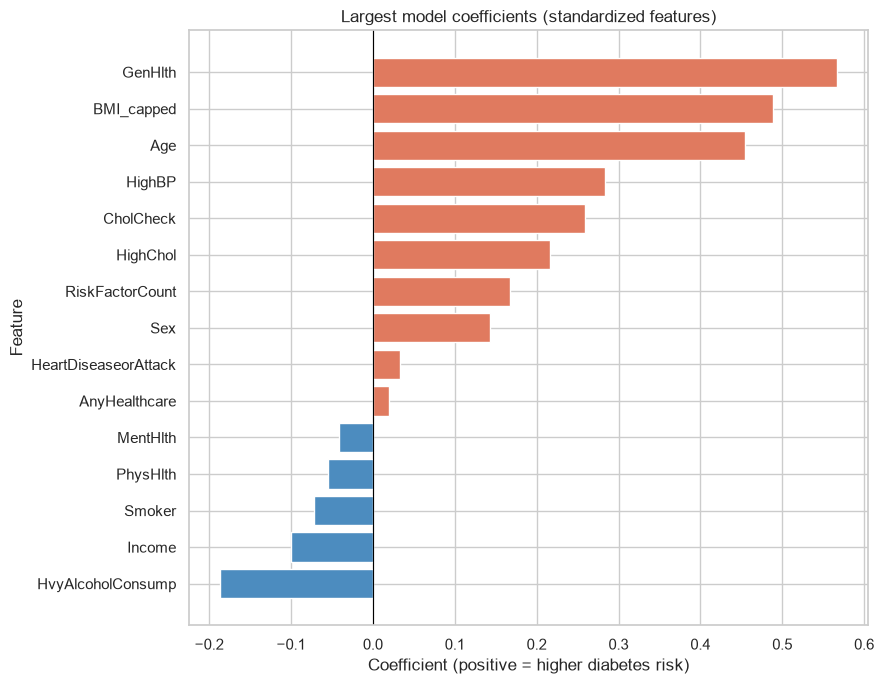

GenHlth              0.567
BMI_capped           0.489
Age                  0.454
HighBP               0.283
CholCheck            0.259
HighChol             0.216
HvyAlcoholConsump   -0.187
RiskFactorCount      0.168
dtype: float64

In [21]:
coefs = pd.Series(baseline[-1].coef_[0], index=features).sort_values()
top = pd.concat([coefs.head(5), coefs.tail(10)])

fig, ax = plt.subplots(figsize=(9, 7))
colors = ["#e07a5f" if v > 0 else "#4c8cbf" for v in top.values]
ax.barh(top.index, top.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Largest model coefficients (standardized features)")
ax.set_xlabel("Coefficient (positive = higher diabetes risk)")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(8).round(3)

Self-rated general health, BMI, age and high blood pressure have the largest positive coefficients, followed by `CholCheck` (having had a cholesterol check) and high cholesterol. This matches what the exploratory charts showed. `CholCheck` ranks high probably because people who see a doctor are more likely to have been diagnosed, not because the check itself causes diabetes. Heavy alcohol use has a negative coefficient, consistent with the lower rate seen earlier. Because some features are correlated with each other, individual coefficients should be read as a rough guide, not as exact effects.

## 7. Conclusions and next steps

In [22]:
display(Markdown(f'''
### Summary of findings

- **Data:** {len(raw):,} responses; {raw.duplicated().sum():,} exact duplicates removed, leaving {len(df):,}. There were no missing values. About {df["Diabetes_binary"].mean():.0%} of respondents have diabetes.
- **EDA:** diabetes risk rises with age, BMI, worse self-rated health, high blood pressure, high cholesterol, heart disease and lower income. Physical activity goes with lower risk.
- **Baseline model:** balanced Logistic Regression finds **{bal["recall"]:.0%}** of people with diabetes (recall) with ROC-AUC **{bal["roc_auc"]:.2f}**, at the cost of many false alarms (precision {bal["precision"]:.0%}).
- **Key lesson:** accuracy would have suggested a "good" model that finds nobody. Recall and ROC-AUC give a more honest picture.
'''))


### Summary of findings

- **Data:** 253,680 responses; 24,206 exact duplicates removed, leaving 229,474. There were no missing values. About 15% of respondents have diabetes.
- **EDA:** diabetes risk rises with age, BMI, worse self-rated health, high blood pressure, high cholesterol, heart disease and lower income. Physical activity goes with lower risk.
- **Baseline model:** balanced Logistic Regression finds **76%** of people with diabetes (recall) with ROC-AUC **0.81**, at the cost of many false alarms (precision 32%).
- **Key lesson:** accuracy would have suggested a "good" model that finds nobody. Recall and ROC-AUC give a more honest picture.


### Limitations
- The data are **self-reported survey answers from 2015**, so they contain reporting errors and may not describe the population today.
- The target mixes **prediabetes and diabetes**, and cannot tell type 1 from type 2.
- Exact duplicate rows were removed, but some of them may have been real, different people.
- The model shows **association, not causation**, and it is a screening aid, not a diagnosis.

### Next steps (Module 24)
- Compare the baseline with a Decision Tree, Random Forest and Gradient Boosting, and tune them with cross-validation.
- Choose the decision threshold using the trade-off between recall and precision.
- Check how the model performs across age and income groups.
- Turn the results into a short non-technical report with recommendations for who to screen first.